<a href="https://colab.research.google.com/github/192412566/mechine-learning-lab/blob/main/Harini_Mech_Learn_Exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch: 0 Loss: 0.341657
Epoch: 1000 Loss: 0.013059
Epoch: 2000 Loss: 0.002574
Epoch: 3000 Loss: 0.001324
Epoch: 4000 Loss: 0.000874
Epoch: 5000 Loss: 0.000646
Epoch: 6000 Loss: 0.00051
Epoch: 7000 Loss: 0.00042
Epoch: 8000 Loss: 0.000356
Epoch: 9000 Loss: 0.000309

Training Completed!
Final Loss: 0.000272


TEST RESULTS

Input	Actual	Predicted Probability	Predicted Class
[0. 0.] 	 0 	 0.0191 		 0
[0. 1.] 	 1 	 0.9843 		 1
[1. 0.] 	 1 	 0.9845 		 1
[1. 1.] 	 0 	 0.0155 		 0

Accuracy: 100.0 %


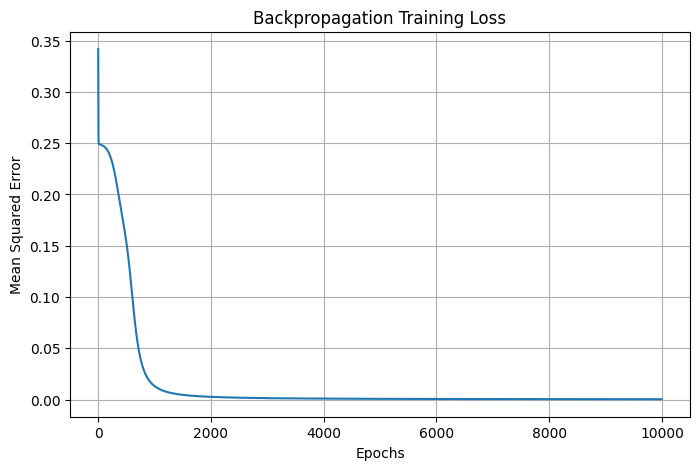



NEW SAMPLE PREDICTION
Input: [0. 1.]
Predicted Probability: 0.9843
Predicted Class: 1


In [2]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION
# Google Colab - No CSV Required
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create Dataset
# ------------------------------------------------------------
# XOR dataset
#
# Input       Output
# -------------------
# 0 0           0
# 0 1           1
# 1 0           1
# 1 1           0
#
# XOR is a good dataset for demonstrating a neural network
# because it is not linearly separable.

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)


# ------------------------------------------------------------
# 2. Define Activation Function
# ------------------------------------------------------------

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# Derivative of sigmoid
def sigmoid_derivative(x):
    return x * (1 - x)


# ------------------------------------------------------------
# 3. Initialize Network
# ------------------------------------------------------------

np.random.seed(42)

# Network architecture:
#
# Input Layer  : 2 neurons
# Hidden Layer : 4 neurons
# Output Layer : 1 neuron

input_neurons = 2
hidden_neurons = 4
output_neurons = 1

# Random weights
W1 = np.random.uniform(
    size=(input_neurons, hidden_neurons)
)

W2 = np.random.uniform(
    size=(hidden_neurons, output_neurons)
)

# Biases
b1 = np.zeros((1, hidden_neurons))
b2 = np.zeros((1, output_neurons))


# ------------------------------------------------------------
# 4. Set Training Parameters
# ------------------------------------------------------------

learning_rate = 0.5
epochs = 10000

loss_history = []


# ------------------------------------------------------------
# 5. Backpropagation Training
# ------------------------------------------------------------

for epoch in range(epochs):

    # ========================================================
    # FORWARD PROPAGATION
    # ========================================================

    # Hidden layer
    hidden_input = np.dot(X, W1) + b1
    hidden_output = sigmoid(hidden_input)

    # Output layer
    output_input = np.dot(hidden_output, W2) + b2
    predicted_output = sigmoid(output_input)


    # ========================================================
    # CALCULATE ERROR
    # ========================================================

    error = y - predicted_output

    # Mean Squared Error
    mse = np.mean(error ** 2)

    loss_history.append(mse)


    # ========================================================
    # BACKPROPAGATION
    # ========================================================

    # Output layer gradient
    output_delta = (
        error *
        sigmoid_derivative(predicted_output)
    )

    # Hidden layer error
    hidden_error = np.dot(
        output_delta,
        W2.T
    )

    # Hidden layer gradient
    hidden_delta = (
        hidden_error *
        sigmoid_derivative(hidden_output)
    )


    # ========================================================
    # UPDATE WEIGHTS AND BIASES
    # ========================================================

    W2 += learning_rate * np.dot(
        hidden_output.T,
        output_delta
    )

    b2 += learning_rate * np.sum(
        output_delta,
        axis=0,
        keepdims=True
    )

    W1 += learning_rate * np.dot(
        X.T,
        hidden_delta
    )

    b1 += learning_rate * np.sum(
        hidden_delta,
        axis=0,
        keepdims=True
    )


    # Print progress
    if epoch % 1000 == 0:

        print(
            "Epoch:",
            epoch,
            "Loss:",
            round(mse, 6)
        )


# ------------------------------------------------------------
# 6. Display Final Loss
# ------------------------------------------------------------

print("\nTraining Completed!")

print(
    "Final Loss:",
    round(loss_history[-1], 6)
)


# ------------------------------------------------------------
# 7. Test the Neural Network
# ------------------------------------------------------------

hidden_output = sigmoid(
    np.dot(X, W1) + b1
)

final_output = sigmoid(
    np.dot(hidden_output, W2) + b2
)

predicted_class = (
    final_output >= 0.5
).astype(int)


# ------------------------------------------------------------
# 8. Display Results
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("TEST RESULTS")
print("=" * 60)

print(
    "\nInput\tActual\tPredicted Probability\tPredicted Class"
)

for i in range(len(X)):

    print(
        X[i],
        "\t",
        int(y[i][0]),
        "\t",
        round(float(final_output[i][0]), 4),
        "\t\t",
        int(predicted_class[i][0])
    )


# ------------------------------------------------------------
# 9. Calculate Accuracy
# ------------------------------------------------------------

accuracy = np.mean(
    predicted_class == y
) * 100

print("\nAccuracy:", accuracy, "%")


# ------------------------------------------------------------
# 10. Plot Training Loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.title(
    "Backpropagation Training Loss"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 11. Test a New Sample
# ------------------------------------------------------------

new_sample = np.array([
    [0, 1]
], dtype=float)

hidden_new = sigmoid(
    np.dot(new_sample, W1) + b1
)

output_new = sigmoid(
    np.dot(hidden_new, W2) + b2
)

new_prediction = (
    output_new >= 0.5
).astype(int)

print("\n")
print("=" * 60)
print("NEW SAMPLE PREDICTION")
print("=" * 60)

print("Input:", new_sample[0])

print(
    "Predicted Probability:",
    round(float(output_new[0][0]), 4)
)

print(
    "Predicted Class:",
    int(new_prediction[0][0])
)